# Khmer Handwriting Recognition 

##  PCA → VQC vs CNN → VQC

In [1]:
import csv
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pennylane as qml
from pennylane import numpy as pnp
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler

sys.path.insert(0, str(Path("../../src").resolve()))
import quantum_model as qm  # noqa: E402

ML_READY_DIR = Path("../../data/3_ready/cnn_alphabet")
SYNTH_DIR = Path("../../data/synthetic_alphabet")
TRAINING_TABLES_DIR = Path("../../results/tables/training")
TABLES_DIR = Path("../../results/tables/accuracy")
CHARTS_DIR = Path("../../results/charts/accuracy")
TABLES_DIR.mkdir(parents=True, exist_ok=True)
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

QUBIT_SIZES = [4, 6, 8]
MAX_EPOCHS = 60
PATIENCE = 15
BATCH_SIZE = 32
LEARNING_RATE = 0.05
SEED = 0

with open(SYNTH_DIR / "chars.json", encoding="utf-8") as f:
    chars_info = json.load(f)
SUBSET_16 = chars_info["subset_16"]

df = pd.read_parquet(ML_READY_DIR / "cleaned_dataset.parquet")
print(f"rows: {len(df)}, classes: {df['text'].nunique()}")

rows: 2640, classes: 33


## Fit PCA per qubit count (train only), transform val/test, scale to [0, π]

In [2]:
def flatten(sub_df):
    return np.stack(sub_df["cleaned"].to_numpy()).reshape(len(sub_df), -1)

pca_data = {}
for n_qubits in QUBIT_SIZES:
    classes = sorted(SUBSET_16) if n_qubits == 4 else sorted(chars_info["all_chars"])
    label_map = {ch: i for i, ch in enumerate(classes)}
    sub_df = df[df["text"].isin(classes)]

    train_df = sub_df[sub_df["split"] == "train"]
    val_df = sub_df[sub_df["split"] == "val"]
    test_df = sub_df[sub_df["split"] == "test"]

    pca = PCA(n_components=n_qubits, random_state=SEED)
    train_pca = pca.fit_transform(flatten(train_df))
    val_pca = pca.transform(flatten(val_df))
    test_pca = pca.transform(flatten(test_df))

    scaler = MinMaxScaler(feature_range=(0, np.pi))
    train_feat = scaler.fit_transform(train_pca)
    val_feat = scaler.transform(val_pca)
    test_feat = scaler.transform(test_pca)

    pca_data[n_qubits] = {
        "train": (pnp.array(train_feat), train_df["text"].map(label_map).to_numpy()),
        "val": (pnp.array(val_feat), val_df["text"].map(label_map).to_numpy()),
        "test": (pnp.array(test_feat), test_df["text"].map(label_map).to_numpy()),
        "n_classes": len(classes),
    }
    print(f"{n_qubits}q -> explained variance: {pca.explained_variance_ratio_.sum():.3f}")

4q -> explained variance: 0.361
6q -> explained variance: 0.404
8q -> explained variance: 0.453


## Train a VQC+head on the PCA features (same architecture, canonical layer count, as 02_train_hybrid.ipynb)

In [3]:
def train_on_features(n_qubits, data):
    X_train, y_train = data["train"]
    X_val, y_val = data["val"]
    X_test, y_test = data["test"]
    n_classes = data["n_classes"]

    qnode = qm.make_qnode(n_qubits, n_layers=qm.N_LAYERS, noise_prob=0.0)
    circuit_weights = qm.init_weights(n_qubits, n_layers=qm.N_LAYERS, seed=SEED)
    head_weight, head_bias, log_scale = qm.init_head_params(n_qubits, n_classes, seed=SEED)
    params = (circuit_weights, head_weight, head_bias, log_scale)

    def class_probs(X, cw, hw, hb, ls):
        feats = pnp.stack(qnode(X, cw), axis=-1)
        return qm.apply_head(feats, hw, hb, ls)

    opt = qml.AdamOptimizer(stepsize=LEARNING_RATE)
    rng = np.random.default_rng(SEED)
    n_train = len(X_train)

    best_val_acc = -1.0
    best_params = params
    epochs_without_improve = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        perm = rng.permutation(n_train)
        X_shuffled, y_shuffled = X_train[perm], y_train[perm]
        for start in range(0, n_train, BATCH_SIZE):
            X_batch = X_shuffled[start:start + BATCH_SIZE]
            y_batch = y_shuffled[start:start + BATCH_SIZE]

            def cost(*p, X_batch=X_batch, y_batch=y_batch):
                return qm.cross_entropy(class_probs(X_batch, *p), y_batch)

            new_params, loss_val = opt.step_and_cost(cost, *params)
            params = tuple(new_params)

        val_acc = qm.accuracy(class_probs(X_val, *params), y_val)
        print(f"[{n_qubits}q-pca] epoch {epoch:2d}  loss={float(loss_val):.4f}  val_acc={val_acc:.3f}")
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_params = tuple(pnp.array(p) for p in params)
            epochs_without_improve = 0
        else:
            epochs_without_improve += 1
            if epochs_without_improve >= PATIENCE:
                print(f"[{n_qubits}q-pca] early stopping at epoch {epoch}")
                break

    test_acc = qm.accuracy(class_probs(X_test, *best_params), y_test)
    print(f"[{n_qubits}q-pca] DONE -> val_acc={best_val_acc:.3f} test_acc={test_acc:.3f}\n")
    return best_val_acc, test_acc


pca_results = []
for n_qubits in QUBIT_SIZES:
    val_acc, test_acc = train_on_features(n_qubits, pca_data[n_qubits])
    pca_results.append({"qubits": n_qubits, "val_accuracy": round(val_acc, 4), "test_accuracy": round(test_acc, 4)})

pd.DataFrame(pca_results)

[4q-pca] epoch  1  loss=1.9037  val_acc=0.375
[4q-pca] epoch  2  loss=1.8222  val_acc=0.401
[4q-pca] epoch  3  loss=1.5179  val_acc=0.385
[4q-pca] epoch  4  loss=1.5192  val_acc=0.349
[4q-pca] epoch  5  loss=1.4351  val_acc=0.396
[4q-pca] epoch  6  loss=1.7613  val_acc=0.385
[4q-pca] epoch  7  loss=1.9654  val_acc=0.370
[4q-pca] epoch  8  loss=1.6492  val_acc=0.396
[4q-pca] epoch  9  loss=1.1476  val_acc=0.354
[4q-pca] epoch 10  loss=1.3457  val_acc=0.411
[4q-pca] epoch 11  loss=1.6279  val_acc=0.438
[4q-pca] epoch 12  loss=1.3140  val_acc=0.401
[4q-pca] epoch 13  loss=1.1888  val_acc=0.370
[4q-pca] epoch 14  loss=1.3817  val_acc=0.375
[4q-pca] epoch 15  loss=1.2413  val_acc=0.359
[4q-pca] epoch 16  loss=1.6123  val_acc=0.401
[4q-pca] epoch 17  loss=1.4208  val_acc=0.391
[4q-pca] epoch 18  loss=1.4010  val_acc=0.401
[4q-pca] epoch 19  loss=1.5471  val_acc=0.312
[4q-pca] epoch 20  loss=1.6118  val_acc=0.359
[4q-pca] epoch 21  loss=1.1058  val_acc=0.385
[4q-pca] epoch 22  loss=1.4786  va

,qubits,val_accuracy,test_accuracy
0,4,0.4375,0.4896
1,6,0.4419,0.4596
2,8,0.5707,0.5404


## Compare against the CNN → VQC results from 02_train_hybrid.ipynb

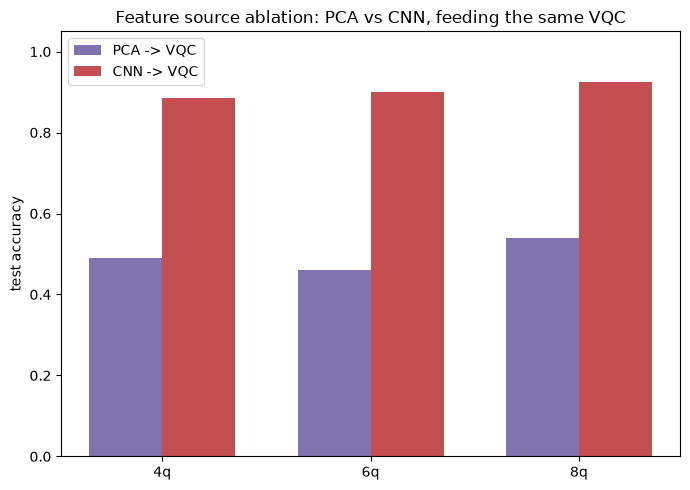

Wrote: ..\..\results\tables\accuracy\pca_vs_cnn.csv
Wrote: ..\..\results\charts\accuracy\pca_vs_cnn.png


,qubits,pca_vqc_test_accuracy,cnn_vqc_test_accuracy
0,4,0.4896,0.8854
1,6,0.4596,0.8990
2,8,0.5404,0.9242


In [4]:
cnn_summary_df = pd.read_csv(TRAINING_TABLES_DIR / "training_summary_alphabet.csv")
cnn_canonical = cnn_summary_df[cnn_summary_df["layers"] == qm.N_LAYERS]

comparison_rows = []
for row in pca_results:
    n_qubits = row["qubits"]
    cnn_row = cnn_canonical[cnn_canonical["qubits"] == n_qubits]
    comparison_rows.append({
        "qubits": n_qubits,
        "pca_vqc_test_accuracy": row["test_accuracy"],
        "cnn_vqc_test_accuracy": float(cnn_row["test_accuracy"].iloc[0]) if len(cnn_row) else None,
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(TABLES_DIR / "pca_vs_cnn.csv", index=False)

plt.figure(figsize=(7, 5))
width = 0.35
x = np.arange(len(comparison_df))
plt.bar(x - width / 2, comparison_df["pca_vqc_test_accuracy"], width, label="PCA -> VQC", color="#8172b2")
plt.bar(x + width / 2, comparison_df["cnn_vqc_test_accuracy"], width, label="CNN -> VQC", color="#c44e52")
plt.xticks(x, [f"{n}q" for n in comparison_df["qubits"]])
plt.ylabel("test accuracy")
plt.title("Feature source ablation: PCA vs CNN, feeding the same VQC")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "pca_vs_cnn.png", dpi=150)
plt.show()

print("Wrote:", TABLES_DIR / "pca_vs_cnn.csv")
print("Wrote:", CHARTS_DIR / "pca_vs_cnn.png")
comparison_df